In [1]:
#importing libraries
import sys
sys.path.append("..")

import json
import joblib
import pandas as pd
import matplotlib.pyplot as plt

from src.data_loader import PROCESSED_DIR
from sklearn.metrics import (average_precision_score, recall_score, precision_score, f1_score,
                             confusion_matrix, ConfusionMatrixDisplay, PrecisionRecallDisplay)

In [2]:
#loading holdout test data
X_test = pd.read_parquet(PROCESSED_DIR / "X_test.parquet")
y_test = pd.read_parquet(PROCESSED_DIR / "y_test.parquet")["readmitted_30"]
print(X_test.shape, y_test.shape)
print("readmission rate:", y_test.mean().round(3))

(29727, 44) (29727,)
readmission rate: 0.114


In [3]:
#loading final model and threshold
final_model = joblib.load("../models/final_model.joblib")
selection = json.load(open("../reports/model_selection_results.json"))
threshold = selection["threshold"]
print(selection["final_model"], selection["best_params"])
print("threshold:", threshold)

Random Forest {'model__max_features': 0.3, 'model__min_samples_leaf': 10}
threshold: 0.4855


In [4]:
#predicting probabilities on test
proba = final_model.predict_proba(X_test)[:, 1]
pred = (proba >= threshold).astype(int)

results = pd.DataFrame({"actual": y_test, "probability": proba.round(3), "predicted": pred})
results.head(10)

,actual,probability,predicted
encounter_id,,,
2278392,0,0.175,0
63768,0,0.295,0
42570,0,0.373,0
84222,0,0.285,0
148530,0,0.316,0
150048,0,0.234,0
182796,0,0.325,0
250872,0,0.351,0
253722,0,0.543,1


In [5]:
#calculating test metrics
test_scores = {
    "pr_auc": average_precision_score(y_test, proba),
    "recall": recall_score(y_test, pred),
    "precision": precision_score(y_test, pred),
    "f1": f1_score(y_test, pred),
}
pd.Series(test_scores).round(3)

pr_auc       0.234
recall       0.440
precision    0.215
f1           0.289
dtype: float64

In [6]:
#pr-auc at every step of the project
baseline = json.load(open("../reports/baseline_results.json"))
pca = json.load(open("../reports/pca_results.json"))
progress = pd.DataFrame({
    "step": ["random guess", "logistic regression (baseline)", "pca + logistic regression", "random forest",
             "gradient boosting", "gradient boosting (tuned)", "random forest (tuned)", "random forest on test"],
    "notebook": ["-", "04", "05", "06", "06", "06", "06", "07"],
    "pr_auc": [y_test.mean(), baseline["cv_pr_auc"], pca["cv_pr_auc"], selection["comparison"]["Random Forest"],
               selection["comparison"]["Gradient Boosting"], selection["tuned_gradient_boosting"],
               selection["tuned_random_forest"], test_scores["pr_auc"]],
})
progress.round(3)

,step,notebook,pr_auc
0,random guess,-,0.114
1,logistic regression (baseline),04,0.213
2,pca + logistic regression,05,0.211
3,random forest,06,0.219
4,gradient boosting,06,0.219
5,gradient boosting (tuned),06,0.223
6,random forest (tuned),06,0.226
7,random forest on test,07,0.234


[[20866  5462]
 [ 1904  1495]]


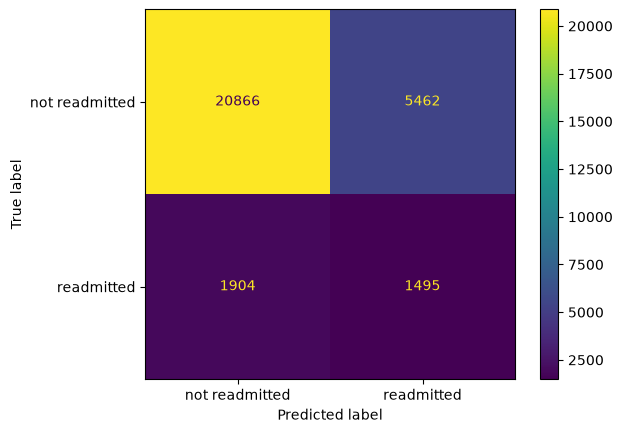

In [7]:
#confusion matrix on test
print(confusion_matrix(y_test, pred))
ConfusionMatrixDisplay.from_predictions(y_test, pred, display_labels=["not readmitted", "readmitted"])
plt.show()

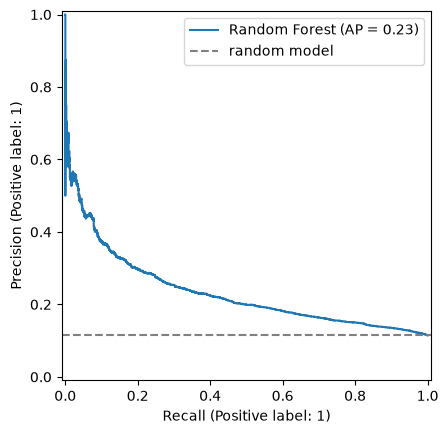

In [8]:
#precision recall curve on test
PrecisionRecallDisplay.from_predictions(y_test, proba, name="Random Forest")
plt.axhline(y_test.mean(), ls="--", color="gray", label="random model")
plt.legend()
plt.show()

In [9]:
#readmission rate by risk group
results["risk_group"] = pd.qcut(results["probability"], 10, labels=False)
results.groupby("risk_group")["actual"].agg(["mean", "count"]).sort_index(ascending=False).round(3)

,mean,count
risk_group,,
9,0.281,2955
8,0.172,2957
7,0.143,3000
6,0.116,2931
5,0.102,3003
4,0.091,2942
3,0.077,3012
2,0.076,2933
1,0.051,3014


In [10]:
#top 10% riskiest patients vs average
top10 = results[results["risk_group"] == 9]
print("readmission rate, all patients:", round(y_test.mean(), 3))
print("readmission rate, top 10% risk:", round(top10["actual"].mean(), 3))
print("share of all readmissions found in top 10%:", round(top10["actual"].sum() / y_test.sum(), 3))

readmission rate, all patients: 0.114
readmission rate, top 10% risk: 0.281
share of all readmissions found in top 10%: 0.244


In [11]:
#saving final test results
final_results = {
    "model": selection["final_model"],
    "params": selection["best_params"],
    "threshold": threshold,
    "test_rows": len(y_test),
    "test_positive_rate": round(float(y_test.mean()), 4),
    "test_scores": pd.Series(test_scores).round(4).to_dict(),
    "cv_pr_auc": selection["cv_pr_auc"],
    "top10_readmission_rate": round(float(top10["actual"].mean()), 4),
}
json.dump(final_results, open("../reports/final_results.json", "w"), indent=2)
final_results

{'model': 'Random Forest',
 'params': {'model__max_features': 0.3, 'model__min_samples_leaf': 10},
 'threshold': 0.4855,
 'test_rows': 29727,
 'test_positive_rate': 0.1143,
 'test_scores': {'pr_auc': 0.2335,
  'recall': 0.4398,
  'precision': 0.2149,
  'f1': 0.2887},
 'cv_pr_auc': 0.2264,
 'top10_readmission_rate': 0.2812}